<a href="https://colab.research.google.com/github/Arunashree13/PDS-assignment/blob/main/PDS_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score



[Scratch] Equation: y = 30.712 + 5.224 * x
[sklearn] Intercept: 31.162, Slope: 5.170
MSE : 0.5981971016302176
R^2 : 0.9989521654506283
Predicted marks for 7.5 hours: 69.93994413407822


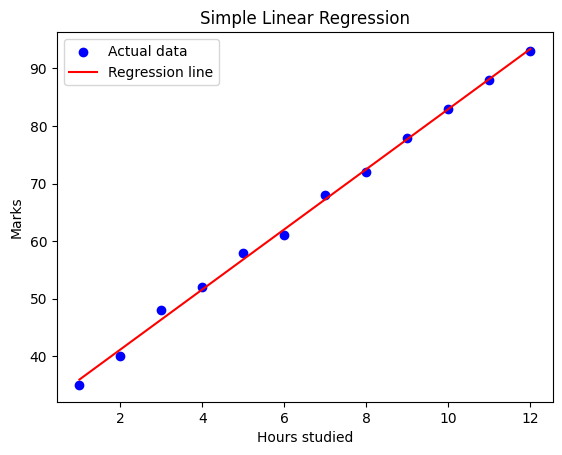

In [ ]:
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype=float)
y = np.array([35, 40, 48, 52, 58, 61, 68, 72, 78, 83, 88, 93], dtype=float)


x_mean, y_mean = X.mean(), y.mean()
b1 = np.sum((X - x_mean) * (y - y_mean)) / np.sum((X - x_mean) ** 2)
b0 = y_mean - b1 * x_mean
print(f"[Scratch] Equation: y = {b0:.3f} + {b1:.3f} * x")

X_train, X_test, y_train, y_test = train_test_split(
    X.reshape(-1, 1), y, test_size=0.25, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"[sklearn] Intercept: {model.intercept_:.3f}, Slope: {model.coef_[0]:.3f}")
print("MSE :", mean_squared_error(y_test, y_pred))
print("R^2 :", r2_score(y_test, y_pred))
print("Predicted marks for 7.5 hours:", model.predict([[7.5]])[0])

plt.scatter(X, y, color="blue", label="Actual data")
plt.plot(X, b0 + b1 * X, color="red", label="Regression line")
plt.xlabel("Hours studied"); plt.ylabel("Marks")
plt.title("Simple Linear Regression"); plt.legend(); plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

rng = np.random.default_rng(0)
n = 300
age = rng.integers(18, 60, n)
salary = rng.integers(15000, 150000, n)
score = 0.12 * (age - 38) + 0.00004 * (salary - 80000) + rng.normal(0, 1, n)
purchased = (score > 0).astype(int)
df = pd.DataFrame({"Age": age, "EstimatedSalary": salary, "Purchased": purchased})
print(df.head())

X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

clf = LogisticRegression()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n", classification_report(y_test, y_pred))

new = sc.transform(pd.DataFrame([[30, 87000]], columns=["Age", "EstimatedSalary"]))
print("New person purchase prediction:", clf.predict(new)[0],
      "| probability:", clf.predict_proba(new)[0][1].round(3))



   Age  EstimatedSalary  Purchased
0   53            30303          1
1   44            16343          0
2   39            28800          0
3   29            64281          0
4   30            29807          0

Confusion Matrix:
 [[35  7]
 [ 4 29]]
Accuracy: 0.8533333333333334

               precision    recall  f1-score   support

           0       0.90      0.83      0.86        42
           1       0.81      0.88      0.84        33

    accuracy                           0.85        75
   macro avg       0.85      0.86      0.85        75
weighted avg       0.86      0.85      0.85        75

New person purchase prediction: 0 | probability: 0.287


=== SVM ===
Accuracy: 0.9333333333333333
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

=== Decision Tree ===
Accuracy: 0.9333333333333333
[[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



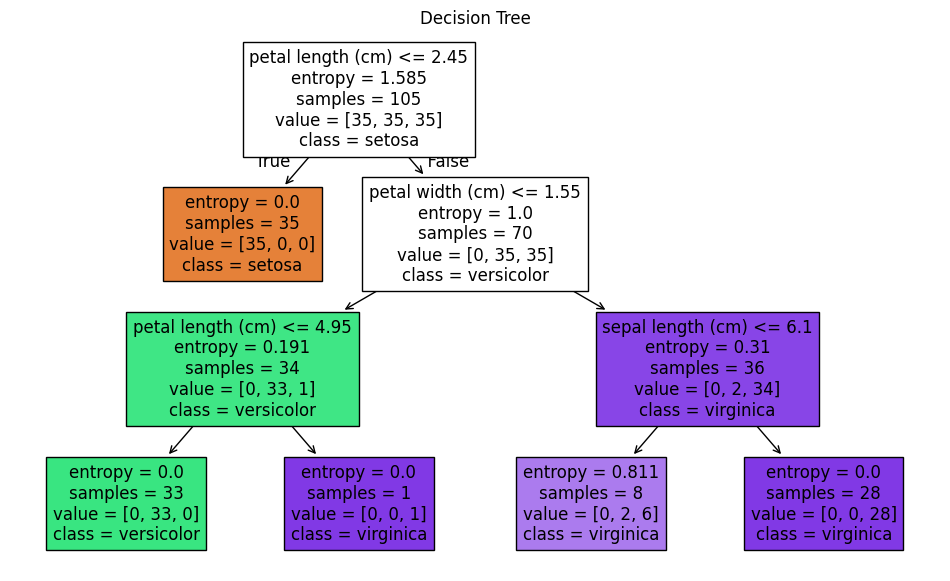

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

svm = SVC(kernel="rbf", C=1.0, gamma="scale")
svm.fit(X_train_s, y_train)
svm_pred = svm.predict(X_test_s)
print("=== SVM ===")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(confusion_matrix(y_test, svm_pred))
print(classification_report(y_test, svm_pred, target_names=iris.target_names))

dt = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
print("=== Decision Tree ===")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred, target_names=iris.target_names))

plt.figure(figsize=(12, 7))
plot_tree(dt, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True)
plt.title("Decision Tree"); plt.show()

Accuracy: 0.9777777777777777
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



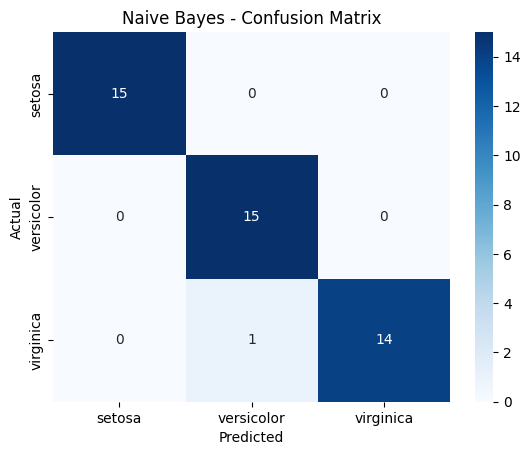

Sample [5.1, 3.5, 1.4, 0.2] -> setosa


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=1, stratify=iris.target)

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred = nb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Naive Bayes - Confusion Matrix"); plt.show()

sample = [[5.1, 3.5, 1.4, 0.2]]
print("Sample", sample[0], "->", iris.target_names[nb.predict(sample)[0]])



In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

transactions = [
    ["bread", "milk", "butter"],
    ["bread", "diaper", "beer", "eggs"],
    ["milk", "diaper", "beer", "cola"],
    ["bread", "milk", "diaper", "beer"],
    ["bread", "milk", "diaper", "cola"],
    ["bread", "butter", "milk"],
    ["milk", "butter", "eggs"],
    ["bread", "milk", "diaper", "butter"],
]

te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print(df.astype(int), "\n")

freq = apriori(df, min_support=0.3, use_colnames=True)
print("Frequent Itemsets:\n", freq, "\n")

rules = association_rules(freq, metric="confidence", min_threshold=0.6)
rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]]
print("Association Rules:\n", rules.sort_values("lift", ascending=False).to_string(index=False))

print("\nStrong rules (lift > 1):\n", rules[rules["lift"] > 1].to_string(index=False))


   beer  bread  butter  cola  diaper  eggs  milk
0     0      1       1     0       0     0     1
1     1      1       0     0       1     1     0
2     1      0       0     1       1     0     1
3     1      1       0     0       1     0     1
4     0      1       0     1       1     0     1
5     0      1       1     0       0     0     1
6     0      0       1     0       0     1     1
7     0      1       1     0       1     0     1 

Frequent Itemsets:
     support               itemsets
0     0.375                 (beer)
1     0.750                (bread)
2     0.500               (butter)
3     0.625               (diaper)
4     0.875                 (milk)
5     0.375         (beer, diaper)
6     0.375        (bread, butter)
7     0.500        (bread, diaper)
8     0.625          (bread, milk)
9     0.500         (milk, butter)
10    0.500         (diaper, milk)
11    0.375  (bread, butter, milk)
12    0.375  (bread, diaper, milk) 

Association Rules:
     antecedents   consequ

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

    Month  Demand  MonthOfYear
0       1   214.0            1
1       2   216.0            2
2       3   232.0            3
3       4   233.0            4
4       5   211.0            5
5       6   207.0            6
6       7   208.0            7
7       8   201.0            8
8       9   202.0            9
9      10   203.0           10
10     11   223.0           11
11     12   235.0           12

Hold-out RMSE: 4.68 | MAPE: 1.61%
Forecast hourly employees needed next month: 305


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

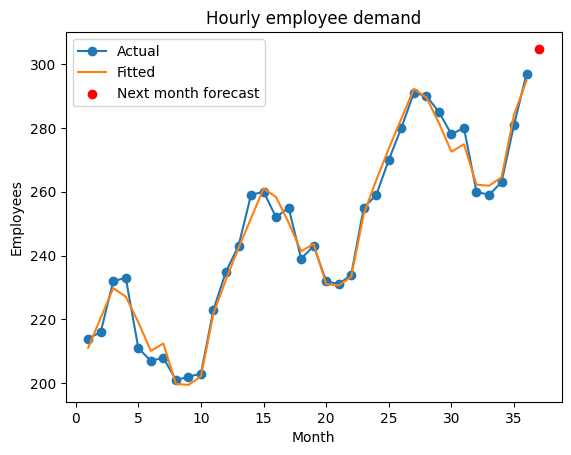

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
months = np.arange(1, 37)
demand = np.round(200 + 2.5 * months + 20 * np.sin(2 * np.pi * months / 12)
                  + rng.normal(0, 6, 36))
hr = pd.DataFrame({"Month": months, "Demand": demand})
hr["MonthOfYear"] = (hr["Month"] - 1) % 12 + 1
print(hr.head(12))

def features(frame):
    X = pd.get_dummies(frame["MonthOfYear"].astype(pd.CategoricalDtype(range(1, 13))),
                       prefix="m", drop_first=True).astype(float)
    X["Trend"] = frame["Month"].values
    return X

train, test = hr.iloc[:30], hr.iloc[30:]
model = LinearRegression().fit(features(train), train["Demand"])
pred = model.predict(features(test))
rmse = np.sqrt(mean_squared_error(test["Demand"], pred))
mape = np.mean(np.abs((test["Demand"] - pred) / test["Demand"])) * 100
print(f"\nHold-out RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

model = LinearRegression().fit(features(hr), hr["Demand"])
nxt = pd.DataFrame({"Month": [37], "MonthOfYear": [1]})
forecast = model.predict(features(nxt))[0]
print(f"Forecast hourly employees needed next month: {forecast:.0f}")

plt.plot(hr["Month"], hr["Demand"], marker="o", label="Actual")
plt.plot(hr["Month"], model.predict(features(hr)), label="Fitted")
plt.scatter([37], [forecast], color="red", zorder=5, label="Next month forecast")
plt.xlabel("Month"); plt.ylabel("Employees"); plt.title("Hourly employee demand")
plt.legend(); plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Shape: (569, 31)
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

--- Logistic Regression ---
Accuracy: 0.9766081871345029
[[ 61   3]
 [  1 106]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


--- Random Forest ---
Accuracy: 0.9649122807017544
[[ 61   3]
 [  3 104]]
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        64
      benign       0.97      0.97      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

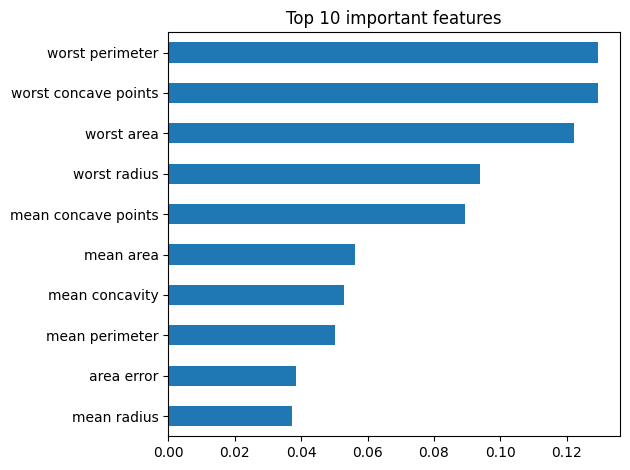

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


New patient diagnosis: benign


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["diagnosis"] = data.target
print("Shape:", df.shape)
print(df["diagnosis"].map({0: "malignant", 1: "benign"}).value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=123, stratify=data.target)
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

logit = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
pred_l = logit.predict(X_test_s)
print("\n--- Logistic Regression ---")
print("Accuracy:", accuracy_score(y_test, pred_l))
print(confusion_matrix(y_test, pred_l))

rf = RandomForestClassifier(n_estimators=200, random_state=123).fit(X_train, y_train)
pred_r = rf.predict(X_test)
print("\n--- Random Forest ---")
print("Accuracy:", accuracy_score(y_test, pred_r))
print(confusion_matrix(y_test, pred_r))
print(classification_report(y_test, pred_r, target_names=data.target_names))

imp = pd.Series(rf.feature_importances_, index=data.feature_names).nlargest(10)
imp.sort_values().plot(kind="barh", title="Top 10 important features")
plt.tight_layout(); plt.show()

patient = X_test[[0]]
label = data.target_names[rf.predict(patient)[0]]
print("\nNew patient diagnosis:", label)
